In [1]:
# !apt-get update -qq && apt-get install -y graphviz

In [2]:
import numpy as np
import pandas as pd
import os
import kagglehub
import pathlib
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, Dense, Dropout
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from pathlib import Path
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, BackupAndRestore
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from tensorflow.keras.models import load_model
import time

2026-10-22 15:17:54.298406: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792682274.317428    1785 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792682274.323329    1785 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792682274.338240    1785 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792682274.338253    1785 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792682274.338255    1785 computation_placer.cc:177] computation placer alr

In [3]:
RAMDOM_STATE = 42
BATCH_SIZE= 32
EPOCHS = 20
image_size = (224, 224)

In [4]:
extensions_valides = (".jpg", ".jpeg", ".png", ".bmp")

labels_par_dossier = {
    "glioma": 0,
    "meningioma": 1,
    "notumor" : 2,
    "pituitary" : 3
}

In [5]:
# Download latest version

dataset_path = Path(
      "/root/.cache/kagglehub/datasets/devana2004/dataset/versions/1/Data"
)

if dataset_path.exists() and any(dataset_path.iterdir()):
      print("✅ Dataset déjà présent dans le cache.")
      print("Chemin :", dataset_path)
      print("Contenu :", [p.name for p in dataset_path.iterdir()])
else:
      print("❌ Dataset absent ou dossier vide.")
      dataset_path = kagglehub.dataset_download("devana2004/dataset")
      dataset_path = dataset_path +'/Data'


print("Path to dataset files:", dataset_path)

Path("cnn").mkdir(parents=True, exist_ok=True)


✅ Dataset déjà présent dans le cache.
Chemin : /root/.cache/kagglehub/datasets/devana2004/dataset/versions/1/Data
Contenu : ['glioma', 'meningioma', 'notumor', 'pituitary']
Path to dataset files: /root/.cache/kagglehub/datasets/devana2004/dataset/versions/1/Data


In [6]:

def check_data(path, extensions_valides, labels_par_dossier):
    num_skiped = 0
    num_corrompu = 0
    images= []
    labels = []
    try:
        data_dir = pathlib.Path(path)
        for folder in data_dir.iterdir():
            if folder.is_dir():
                for file in folder.iterdir():
                    if folder.name in labels_par_dossier.keys():
                        if not file.is_file():
                            continue

                        if file.is_file() and not file.name.lower().endswith(extensions_valides):
                            num_skiped +=1
                            continue

                        else:
                            image = cv2.imread(str(file))

                            if image is None:
                                num_corrompu +=1
                                continue
                            
                            else:
                                image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
                                images.append(image)
                                label = labels_par_dossier[folder.name]
                                labels.append(label)

        print('nombre de fichiers invlaid', num_skiped)
        print('nombre de fichiers corrompus', num_corrompu)
    except (FileNotFoundError):
        print("Erreur : Le fichier n'existe pas.")
    except Exception as e:
        # Capture toute autre erreur inattendue
        print(f"Erreur inattendue : {e}")
    return images, labels

images, labels = check_data(dataset_path, extensions_valides,  labels_par_dossier)

nombre de fichiers invlaid 0
nombre de fichiers corrompus 0


In [7]:
def preparing_data(image_size):
    images_resized =[]
    for image in images:
        resized = cv2.resize(image, image_size, interpolation=cv2.INTER_LINEAR)
        images_resized.append(resized)
    
    images_array_2d = np.array(images_resized)
    
    labeles_array_2d = np.array(labels)
    
    return images_array_2d, labeles_array_2d

images_array_2d, labeles_array_2d = preparing_data(image_size)
print(images_array_2d.shape, labeles_array_2d.shape)

(7023, 224, 224, 3) (7023,)


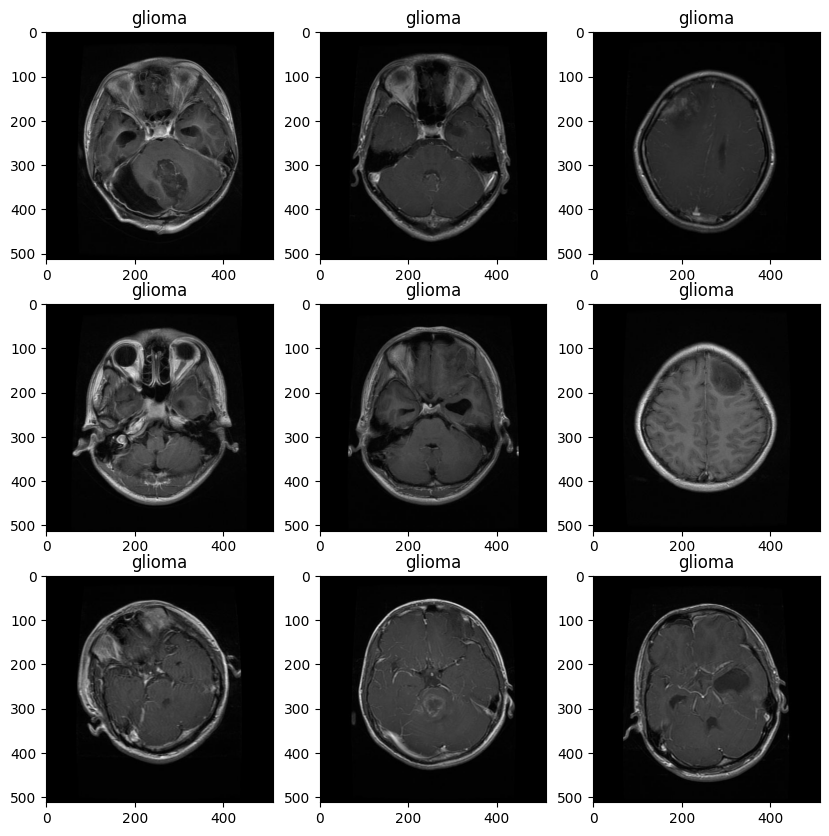

glioma : 1621 images
meningioma : 1645 images
notumor : 2000 images
pituitary : 1757 images


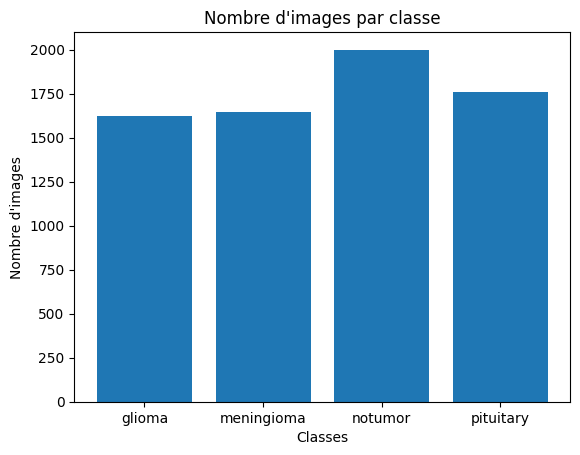

<Figure size 640x480 with 0 Axes>

In [8]:
plt.figure(figsize=(10,10))
n_images = min(9, len(images))

for i in range(n_images):
    ax = plt.subplot(3,3,i+1)
    image_rgb = cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB)
    plt.imshow(image_rgb)
    nom_class = next((k for k, v in labels_par_dossier.items() if v == labels[i]), None)
    plt.title(nom_class)
plt.show()
plt.savefig('/cnn/example1.png')

effectifs = Counter(labels)

noms_classes = list(labels_par_dossier.keys())
nombres_images = [
    effectifs[labels_par_dossier[nom]]
    for nom in noms_classes
]

for nom, nombre in zip(noms_classes, nombres_images):
    print(f'{nom} : {nombre} images')

plt.bar(noms_classes, nombres_images)
plt.title("Nombre d'images par classe")
plt.xlabel('Classes')
plt.ylabel("Nombre d'images")
plt.show()
plt.savefig('/cnn/image_par_class.png')

In [9]:
def spliting_data(X, y):
    X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RAMDOM_STATE)
    X_test, X_val, y_test, y_val = train_test_split(X_tmp, y_tmp, test_size=0.5,  stratify=y_tmp, random_state=RAMDOM_STATE)
    print(X_train.shape, X_test.shape, X_val.shape)
    print(y_train.shape, y_test.shape, y_val.shape)

    return  X_train, X_test, X_val, y_train, y_test, y_val


X_train, X_test, X_val, y_train, y_test, y_val = spliting_data(images_array_2d, labeles_array_2d)

print("X_train :", type(X_train))
print("Shape :", X_train.shape)
print("Type des données :", X_train.dtype)
print("Taille en mémoire :", round(X_train.nbytes / 1024**3, 2), "GB")

print("y_train :", np.asarray(y_train).shape)
print("GPU détecté :", tf.config.list_physical_devices("GPU"))

# def  normalisation(X, seuil):
#     return X.astype('float32') / seuil


def prep(X, y, training=True):
    # X = normalisation(X, 255.0)
    
    X_ds = tf.data.Dataset.from_tensor_slices((X, y))

    if training:
        X_ds = X_ds.shuffle(buffer_size=X_ds.cardinality())
    
    X_ds = X_ds.batch(batch_size=BATCH_SIZE)

    X_ds = X_ds.map(
        lambda images, labels: (
            tf.cast(images, tf.float32) / 255.0,
            labels
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return X_ds.prefetch(buffer_size=tf.data.AUTOTUNE)



Train_ds =  prep(X_train, y_train, training=True)
Test_ds = prep(X_test, y_test, training=False)
Val_ds = prep(X_val, y_val, training=False)
print(Train_ds, Test_ds, Val_ds)

(5618, 224, 224, 3) (702, 224, 224, 3) (703, 224, 224, 3)
(5618,) (702,) (703,)
X_train : <class 'numpy.ndarray'>
Shape : (5618, 224, 224, 3)
Type des données : uint8
Taille en mémoire : 0.79 GB
y_train : (5618,)
GPU détecté : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1792682292.853454    1785 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10258 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:03:00.0, compute capability: 8.6
2026-10-22 15:18:12.855450: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 845666304 exceeds 10% of free system memory.
2026-10-22 15:18:13.472871: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 845666304 exceeds 10% of free system memory.


<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))> <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))> <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>


In [10]:
for image_batch, label_batch in Train_ds:
    print(image_batch.shape)
    print(label_batch.shape)
    break

2026-10-22 15:18:14.461479: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 845666304 exceeds 10% of free system memory.


(32, 224, 224, 3)
(32,)


In [11]:
for images, labels in Train_ds.take(1):
      print("Forme des images :", images.shape)
      print("Valeur minimale :", float(tf.reduce_min(images)))
      print("Valeur maximale :", float(tf.reduce_max(images)))
      print("Labels :", labels[:10].numpy())

2026-10-22 15:18:15.286419: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 845666304 exceeds 10% of free system memory.


Forme des images : (32, 224, 224, 3)
Valeur minimale : 0.0
Valeur maximale : 1.0
Labels : [2 1 1 2 0 0 2 0 3 0]


2026-10-22 15:18:15.817584: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [12]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(
        height_factor=(-0.2, 0.2),
        width_factor=(-0.2, 0.2)
    ),
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),
    layers.RandomZoom(0.1)
], name="data_augmentation")

2026-10-22 15:18:16.421607: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 845666304 exceeds 10% of free system memory.
2026-10-22 15:18:19.191917: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


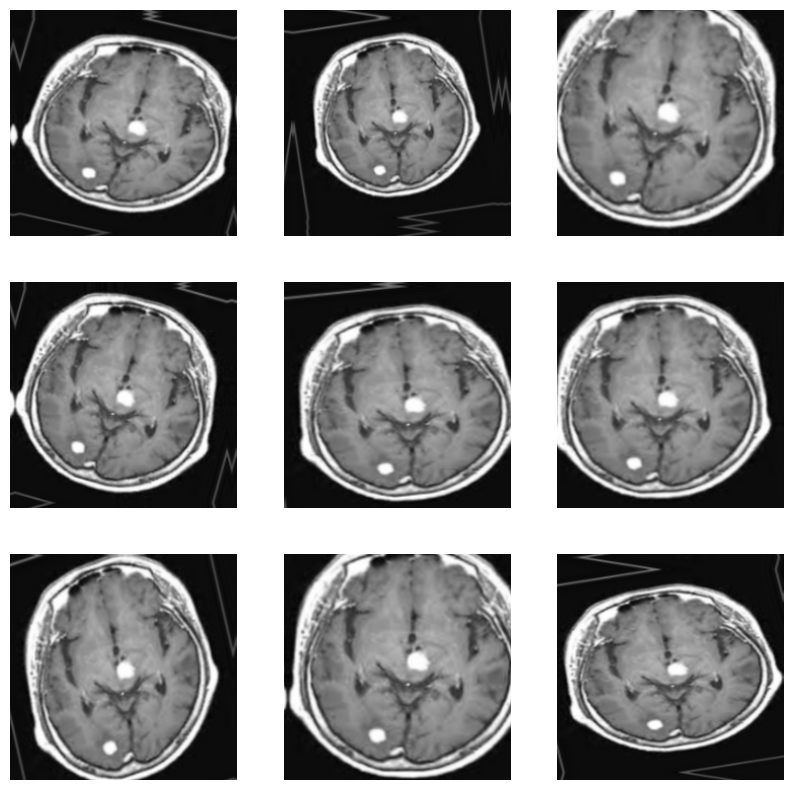

In [13]:
for image, _ in Train_ds.take(1):
      plt.figure(figsize=(10,10))
      first_image = image[0]
      for i in range(9):
            ax = plt.subplot(3, 3, i+1)
            augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
            plt.imshow(augmented_image[0])
            plt.axis('off')
            plt.savefig('cnn/image_apres_data_augmentation.png')

In [14]:
model = models.Sequential()
model.add(layers.Input(shape=(224, 224, 3)))
model.add(data_augmentation)
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(4))

/venv/main/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 173056)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │    11,075,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,132,228 (42.47 MB)

 Trainable params: 11,132,228 (42.47 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
len(model.trainable_variables)

10

In [17]:
model.compile(optimizer='adam',
            loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
            metrics=['accuracy'])

In [18]:
loss0, accuracy0 = model.evaluate(Val_ds)
print('initial loss {:.2f}'.format(loss0))
print('initial accuracy {:.2f}'.format(accuracy0))

I0000 00:00:1792682301.747073    1924 cuda_dnn.cc:529] Loaded cuDNN version 90300


22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.2380 - loss: 1.3870
initial loss 1.38
initial accuracy 0.25


In [19]:
# Path("models").mkdir(parents=True, exist_ok=True)
output_dir = Path("/cnn/models")
backup_dir = Path("/cnn/backup")

output_dir.mkdir(parents=True, exist_ok=True)
backup_dir.mkdir(parents=True, exist_ok=True)

In [20]:


# checkpoint = ModelCheckpoint(
#     filepath=str(output_dir / "model_epoch_{epoch:03d}.keras"),
#     monitor="val_accuracy",
#     save_best_only=False,
#     save_weights_only=False,
#     save_freq="epoch",
#     verbose=1
# )
checkpoint_best = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(output_dir / "best_model.keras"),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)
callback = EarlyStopping(monitor='val_loss',patience=4, restore_best_weights=True)
backup = BackupAndRestore(
    '/cnn/backup/', save_freq="epoch", double_checkpoint=True, delete_checkpoint=False
)

In [21]:
debut = time.time()

history = model.fit(Train_ds, epochs=EPOCHS, 
                  validation_data=(Val_ds), batch_size=BATCH_SIZE, callbacks=[callback, backup, checkpoint_best])

fin = time.time()

duree = fin - debut

print(f"Durée de l'entraînement : {duree:.2f} secondes")
print(f"Durée en minutes : {duree / 60:.2f} minutes")

Epoch 1/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.4952 - loss: 1.2908
Epoch 1: val_loss improved from inf to 0.68362, saving model to /cnn/models/best_model.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 12s 50ms/step - accuracy: 0.4957 - loss: 1.2893 - val_accuracy: 0.7653 - val_loss: 0.6836
Epoch 2/20
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7144 - loss: 0.7279
Epoch 2: val_loss improved from 0.68362 to 0.57405, saving model to /cnn/models/best_model.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 8s 46ms/step - accuracy: 0.7145 - loss: 0.7276 - val_accuracy: 0.7866 - val_loss: 0.5741
Epoch 3/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.7706 - loss: 0.5915
Epoch 3: val_loss improved from 0.57405 to 0.50148, saving model to /cnn/models/best_model.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - accuracy: 0.7707 - loss: 0.5915 - val_accuracy: 0.7909 - val_loss: 0.5015
Epoch 4/20
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7967 - loss: 0.5315
Epoch 4: v

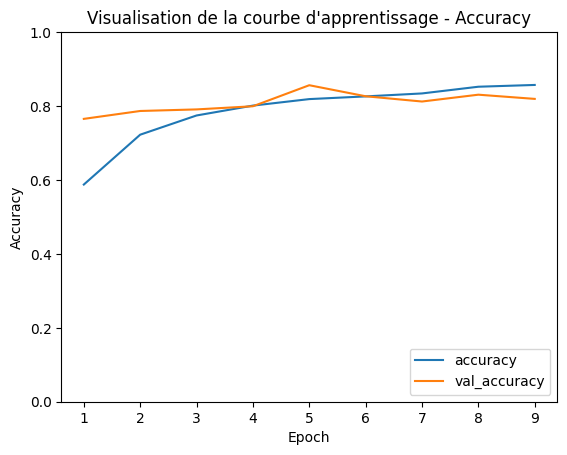

In [38]:
epochs = range(1, len(history.history['val_accuracy']) + 1)
# print(len(history.history['val_accuracy']))
plt.plot(epochs, history.history['accuracy'], label='accuracy')
plt.plot(epochs, history.history['val_accuracy'], label = 'val_accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
plt.title("Visualisation de la courbe d'apprentissage - Accuracy")
plt.savefig("/cnn/accuracy_visualisation.png")

22/22 - 0s - 20ms/step - accuracy: 0.8447 - loss: 0.4151


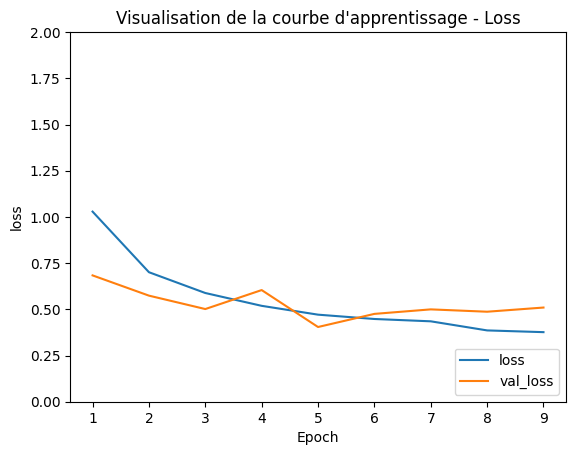

In [42]:
plt.plot(epochs, history.history['loss'], label='loss')
plt.plot(epochs, history.history['val_loss'], label = 'val_loss')
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.ylim([0, 2])
plt.title("Visualisation de la courbe d'apprentissage - Loss")
plt.legend(loc='lower right')
plt.savefig("/cnn/loss_visualisation.png")

test_loss, test_acc = model.evaluate(Test_ds, verbose=2)

In [ ]:
Y = model.predict(Test_ds)
y_pred=np.argmax(Y, axis=1)


22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


array([1, 0, 2, 3, 3, 1, 0, 1, 3, 1, 0, 0, 0, 1, 3, 2, 0, 1, 1, 2, 3, 3,
       3, 0, 3, 3, 3, 0, 2, 0, 3, 2, 2, 0, 1, 3, 3, 1, 1, 3, 2, 2, 0, 3,
       3, 3, 2, 1, 3, 0, 2, 3, 3, 3, 2, 2, 1, 2, 3, 0, 0, 2, 3, 2, 3, 2,
       2, 0, 2, 2, 2, 3, 1, 0, 1, 3, 3, 0, 2, 2, 3, 1, 0, 3, 3, 2, 3, 3,
       2, 1, 0, 2, 0, 1, 2, 3, 2, 1, 2, 1, 3, 0, 3, 2, 0, 1, 0, 1, 2, 3,
       2, 2, 3, 0, 2, 1, 2, 0, 0, 0, 2, 3, 3, 3, 0, 1, 3, 0, 3, 2, 1, 2,
       3, 1, 0, 0, 2, 2, 2, 2, 2, 3, 3, 3, 3, 0, 1, 1, 2, 3, 3, 0, 2, 1,
       2, 2, 2, 1, 0, 0, 2, 3, 3, 2, 0, 3, 2, 0, 1, 3, 3, 1, 1, 0, 3, 1,
       1, 1, 1, 3, 2, 2, 2, 0, 3, 1, 2, 2, 2, 3, 3, 1, 1, 0, 3, 2, 3, 3,
       2, 1, 0, 1, 0, 3, 0, 2, 3, 2, 1, 3, 0, 3, 1, 3, 2, 3, 2, 2, 1, 2,
       2, 3, 0, 0, 0, 3, 1, 1, 1, 2, 3, 0, 2, 0, 0, 3, 3, 0, 1, 2, 1, 2,
       3, 1, 0, 2, 2, 3, 3, 2, 3, 2, 2, 0, 3, 2, 2, 1, 1, 2, 1, 3, 3, 1,
       2, 0, 2, 3, 3, 3, 0, 0, 2, 3, 0, 2, 1, 3, 3, 0, 2, 2, 1, 0, 0, 1,
       2, 0, 3, 1, 2, 3, 0, 1, 1, 2, 0, 2, 2, 0, 0,

In [ ]:
y_true = np.concatenate([
    labels.numpy() for  images, labels in Test_ds
])

array([1, 0, 2, 3, 3, 1, 0, 1, 3, 1, 0, 0, 0, 1, 3, 2, 0, 1, 1, 2, 3, 3,
       3, 0, 3, 3, 3, 0, 2, 0, 3, 2, 2, 0, 1, 3, 3, 1, 1, 3, 2, 2, 0, 3,
       3, 3, 2, 1, 3, 0, 2, 3, 3, 3, 2, 2, 1, 2, 3, 0, 0, 2, 3, 2, 3, 2,
       2, 0, 2, 2, 2, 3, 1, 0, 1, 3, 3, 0, 2, 2, 3, 1, 0, 3, 3, 2, 3, 3,
       2, 1, 0, 2, 0, 1, 2, 3, 2, 1, 2, 1, 3, 0, 3, 2, 0, 1, 0, 1, 2, 3,
       2, 2, 3, 0, 2, 1, 2, 0, 0, 0, 2, 3, 3, 3, 0, 1, 3, 0, 3, 2, 1, 2,
       3, 1, 0, 0, 2, 2, 2, 2, 2, 3, 3, 3, 3, 0, 1, 1, 2, 3, 3, 0, 2, 1,
       2, 2, 2, 1, 0, 0, 2, 3, 3, 2, 0, 3, 2, 0, 1, 3, 3, 1, 1, 0, 3, 1,
       1, 1, 1, 3, 2, 2, 2, 0, 3, 1, 2, 2, 2, 3, 3, 1, 1, 0, 3, 2, 3, 3,
       2, 1, 0, 1, 0, 3, 0, 2, 3, 2, 1, 3, 0, 3, 1, 3, 2, 3, 2, 2, 1, 2,
       2, 3, 0, 0, 0, 3, 1, 1, 1, 2, 3, 0, 2, 0, 0, 3, 3, 0, 1, 2, 1, 2,
       3, 1, 0, 2, 2, 3, 3, 2, 3, 2, 2, 0, 3, 2, 2, 1, 1, 2, 1, 3, 3, 1,
       2, 0, 2, 3, 3, 3, 0, 0, 2, 3, 0, 2, 1, 3, 3, 0, 2, 2, 1, 0, 0, 1,
       2, 0, 3, 1, 2, 3, 0, 1, 1, 2, 0, 2, 2, 0, 0,

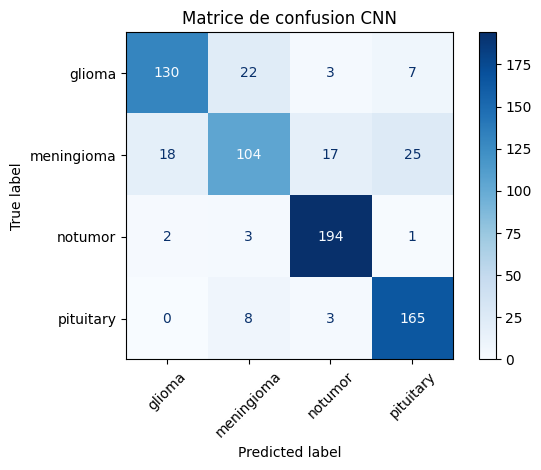

<Figure size 640x480 with 0 Axes>

In [44]:
cm = confusion_matrix(y_true, y_pred)

# effectifs = Counter(labels)

noms_classes = list(labels_par_dossier.keys())

cms = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=noms_classes)
cms.plot(cmap='Blues', xticks_rotation=45)
plt.title("Matrice de confusion CNN")
plt.tight_layout()
plt.show()
plt.savefig("/cnn/matrice_confusion.png")


In [45]:
print(classification_report(y_true, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.87      0.80      0.83       162
           1       0.76      0.63      0.69       164
           2       0.89      0.97      0.93       200
           3       0.83      0.94      0.88       176

    accuracy                           0.84       702
   macro avg       0.84      0.84      0.83       702
weighted avg       0.84      0.84      0.84       702



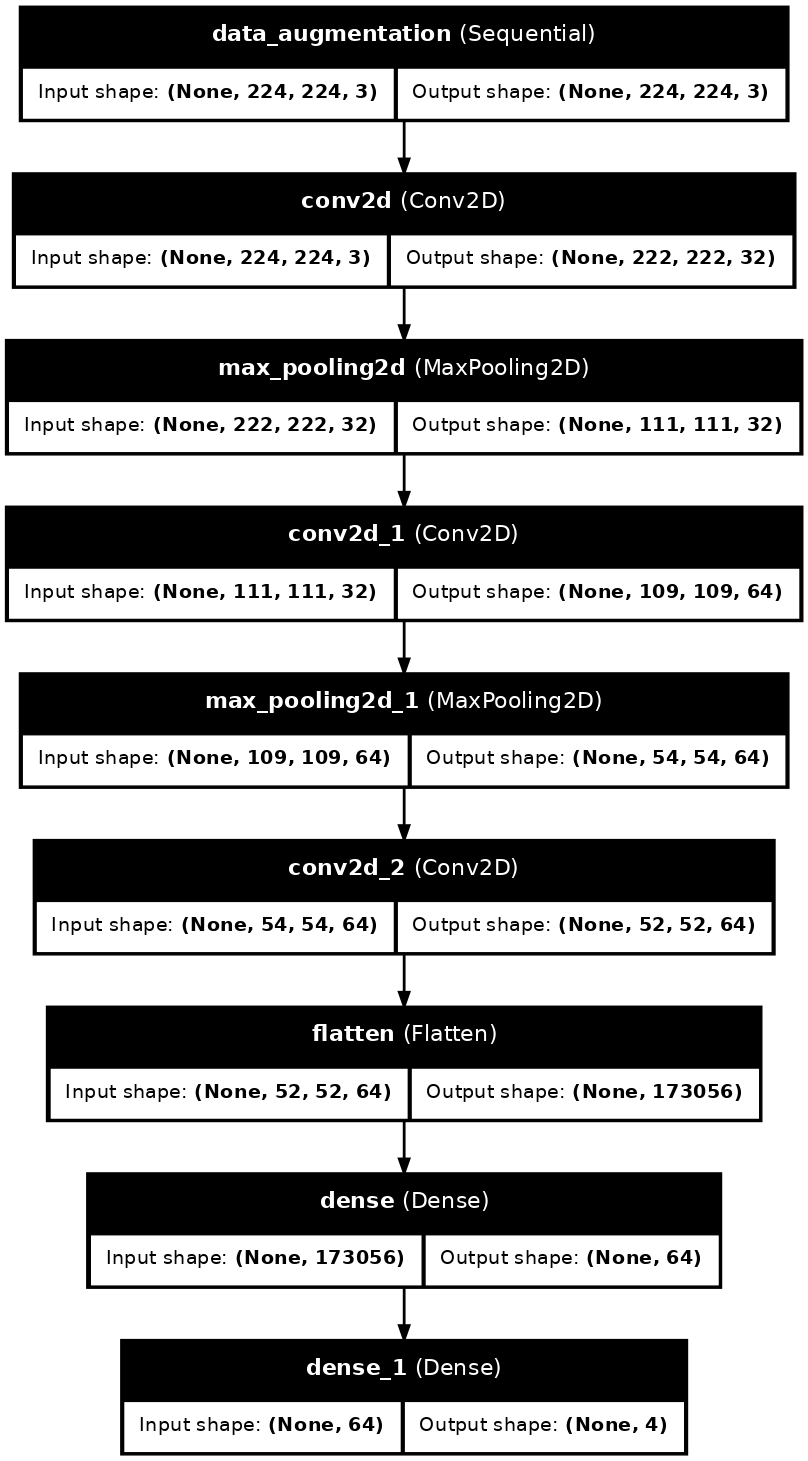

In [50]:
# !apt-get update -qq && apt-get install -y graphviz
from IPython.display import Image, display
out_dir = Path("/cnn/tmp")
out_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path1 = output_dir / "architecture_model_cnn.png"
tf.keras.utils.plot_model(model, to_file=str(checkpoint_path1), show_shapes=True,show_layer_names=True,
dpi=100
)

display(Image(filename=checkpoint_path1))

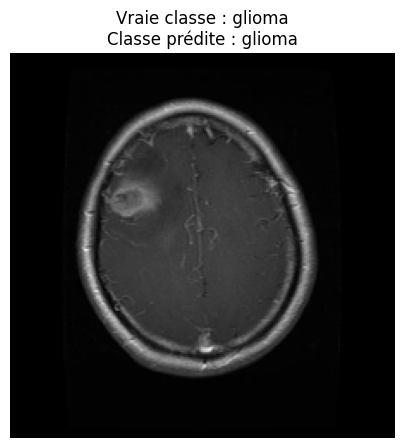

<Figure size 640x480 with 0 Axes>

In [47]:
i = len(y_true) - 3

# Récupérer les images du dataset dans le même ordre
images_all = np.concatenate([
    images.numpy() for images, labels in Test_ds
])

class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']

# Afficher l'image exacte
plt.figure(figsize=(5, 5))
plt.imshow(images_all[i])
plt.title(
    f"Vraie classe : {class_names[int(y_true[i])]}\n"
    f"Classe prédite : {class_names[int(y_pred[i])]}"
)
plt.axis("off")
plt.show()
plt.savefig("/cnn/tru_predict_image.png")


In [48]:
best_model = load_model(output_dir / "best_model.keras" )
best_model.summary()
test_loss, test_accuracy = best_model.evaluate(Test_ds)

print("Test accuracy :", test_accuracy)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 173056)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │    11,075,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,396,686 (127.40 MB)

 Trainable params: 11,132,228 (42.47 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,264,458 (84.93 MB)

22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.8226 - loss: 0.4408
Test accuracy : 0.8447293639183044


In [ ]:
import json
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Les classes doivent respecter l'ordre utilisé pendant l'entraînement
class_names = [
    "Gliome",
    "Méningiome",
    "Aucune tumeur",
    "Tumeur hypophysaire"
]

# 1. Récupérer les vraies classes du jeu de test
y_true = np.concatenate([
    labels.numpy() for images, labels in Test_ds
])

# Gérer les labels one-hot, si nécessaire
if y_true.ndim > 1:
    y_true = np.argmax(y_true, axis=1)

# 2. Prédictions du modèle
y_prob = model.predict(Test_ds)
y_pred = np.argmax(y_prob, axis=1)

# 3. Métriques globales
metrics = {
    "model" : "cnn",
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "precision": float(
        precision_score(y_true, y_pred, average="weighted", zero_division=0)
    ),
    "recall": float(
        recall_score(y_true, y_pred, average="weighted", zero_division=0)
    ),
    "f1_score": float(
        f1_score(y_true, y_pred, average="weighted", zero_division=0)
    ),

    # 4. Matrice de confusion
    "confusion_matrix": confusion_matrix(
        y_true, y_pred, labels=range(len(class_names))
    ).tolist(),

    "class_names": class_names,

    # 5. Rapport détaillé par classe
    "classification_report": classification_report(
        y_true,
        y_pred,
        labels=range(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
}

# 6. Courbes d'apprentissage enregistrées pendant model.fit()
if "history" in globals() and history is not None:
    metrics["learning_curves"] = {
        key: [float(value) for value in values]
        for key, values in history.history.items()
    }

# 7. Enregistrer le JSON dans le projet
Path("/cnn/metrics").mkdir(parents=True, exist_ok=True)
output_path = Path("/cnn/metrics/metrics_cnn.json")

with output_path.open("w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4, ensure_ascii=False)

print(f"Métriques sauvegardées dans : {output_path.resolve()}")

22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
Métriques sauvegardées dans : /cnn/metrics/metrics_cnn.json
